In [1]:
BRANCH = "phase-7-test"

%cd /tmp
!rm -rf damage-detection
!git clone -b {BRANCH} https://github.com/azrairemd/damage-detection.git
%cd damage-detection
!pip install -q -r requirements.txt
!pip install -q -e .

/tmp
Cloning into 'damage-detection'...
remote: Enumerating objects: 360, done.
remote: Counting objects: 100% (199/199), done.Counting objects:  95% (190/199)
remote: Compressing objects: 100% (167/167), done.
remote: Total 360 (delta 76), reused 110 (delta 31), pack-reused 161 (from 1)
Receiving objects: 100% (360/360), 13.28 MiB | 34.69 MiB/s, done.
Resolving deltas: 100% (155/155), done.
/tmp/damage-detection
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for damage-detection (pyproject.toml) ... done


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from src.data.labels import load_label, parse_buildings
from src.data.xbd import get_label_path, load_pair
from src.data.masks import make_mask

In [3]:
ROOT = "/kaggle/input/datasets/qianlanzz/xbd-dataset/xbd"

In [5]:
CLASS_NAMES = {1: "No damage", 2: "Minor damage", 3: "Major damage", 4: "Destroyed"}
MIN_AREA = 800 

pairs = pd.read_csv("splits/train.csv").sample(frac=1, random_state=0)   


def find_example(damage, n=0):
    found = 0
    for folder, image_id in zip(pairs["folder"], pairs["image_id"]):
        label = load_label(get_label_path(ROOT, folder, image_id, "post"))
        for building in parse_buildings(label):
            if building.damage == damage and building.area() > MIN_AREA:
                if found == n:
                    return folder, image_id, building, label
                found += 1


examples = {c: find_example(c) for c in CLASS_NAMES}
for c, (folder, image_id, building, label) in examples.items():
    print(f"{CLASS_NAMES[c]:13s} {image_id:35s} area {building.area():.0f}")

No damage     hurricane-michael_00000195          area 1495
Minor damage  hurricane-michael_00000195          area 1010
Major damage  hurricane-michael_00000195          area 1700
Destroyed     hurricane-matthew_00000348          area 2207


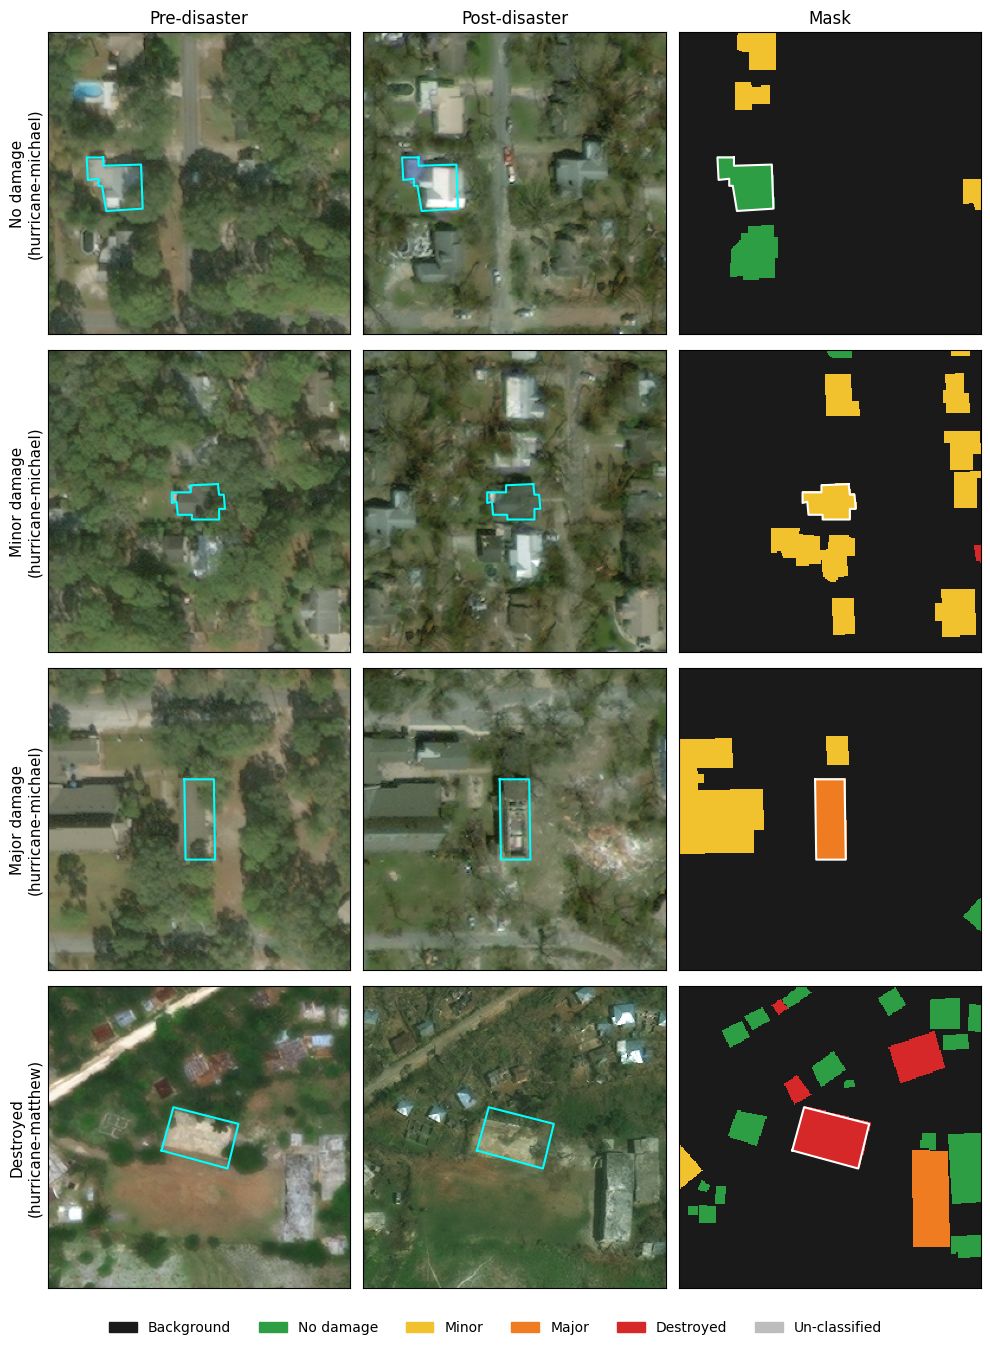

In [9]:
CROP = 256

MASK_COLORS = ["#1a1a1a", "#2e9e44", "#f2c12e", "#f07c22", "#d62828", "#bdbdbd"]
MASK_LABELS = ["Background", "No damage", "Minor", "Major", "Destroyed", "Un-classified"]
cmap = ListedColormap(MASK_COLORS)


def crop_corner(building, image_size=1024):
    cx, cy = building.polygon.centroid.x, building.polygon.centroid.y
    x0 = int(np.clip(cx - CROP / 2, 0, image_size - CROP))
    y0 = int(np.clip(cy - CROP / 2, 0, image_size - CROP))
    return x0, y0


def draw_outline(ax, polygon, x0, y0, color):
    parts = polygon.geoms if polygon.geom_type == "MultiPolygon" else [polygon]
    for part in parts:
        xs, ys = part.exterior.xy
        ax.plot(np.array(xs) - x0, np.array(ys) - y0, color=color, linewidth=1.5)


fig, axes = plt.subplots(4, 3, figsize=(10, 13.5))

for row, (c, (folder, image_id, building, label)) in enumerate(examples.items()):
    pre, post = load_pair(ROOT, folder, image_id)
    mask = make_mask(parse_buildings(label))
    mask = np.where(mask == 255, 5, mask)   # 255 -> 5, so that un-classified gets the last color

    x0, y0 = crop_corner(building)
    window = (slice(y0, y0 + CROP), slice(x0, x0 + CROP))

    axes[row, 0].imshow(pre[window])
    axes[row, 1].imshow(post[window])
    axes[row, 2].imshow(mask[window], cmap=cmap, vmin=-0.5, vmax=5.5, interpolation="nearest")

    draw_outline(axes[row, 0], building.polygon, x0, y0, "cyan")
    draw_outline(axes[row, 1], building.polygon, x0, y0, "cyan")
    draw_outline(axes[row, 2], building.polygon, x0, y0, "white")

    disaster = label["metadata"]["disaster"]
    axes[row, 0].set_ylabel(f"{CLASS_NAMES[c]}\n({disaster})", fontsize=11)

for ax, title in zip(axes[0], ["Pre-disaster", "Post-disaster", "Mask"]):
    ax.set_title(title, fontsize=12)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

handles = [Patch(color=col, label=lab) for col, lab in zip(MASK_COLORS, MASK_LABELS)]
fig.legend(handles=handles, loc="lower center", ncol=6, frameon=False)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("/kaggle/working/damage_examples.png", dpi=150, bbox_inches="tight")
plt.show()